In [69]:
from pydoc import describe

from IPython.display import display
import pandas as pd
from pymupdf import dest_is_valid_page
from rich.jupyter import display

import matplotlib.pyplot as plt

# What is it?

Data kepuasan cutomer terkait maskapai.. Targetnya adalah apakah cutomer puas atau tidak puas

# Dataset Description
The dataset for this competition (both train and test) was inspired by the Airline satisfaction dataset. Feature distributions are close to, but not exactly the same, as the original.



Files
train.csv - the training set, with satisfaction as target
test.csv - the test set, used to predict the probability for satisfaction
sample_submission.csv - a sample submission file in the correct format

In [70]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

print(train.info())
print(test.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699635 entries, 0 to 699634
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   id                                 699635 non-null  int64  
 1   Age                                699635 non-null  int64  
 2   Flight Distance                    699635 non-null  int64  
 3   Inflight wifi service              699635 non-null  int64  
 4   Departure/Arrival time convenient  699635 non-null  int64  
 5   Ease of Online booking             699635 non-null  int64  
 6   Gate location                      699635 non-null  int64  
 7   Food and drink                     699635 non-null  int64  
 8   Online boarding                    699635 non-null  int64  
 9   Seat comfort                       699635 non-null  int64  
 10  Inflight entertainment             699635 non-null  int64  
 11  On-board service                   6996

In [71]:
print(train.isnull().sum())
print(test.isnull().sum())


id                                     0
Age                                    0
Flight Distance                        0
Inflight wifi service                  0
Departure/Arrival time convenient      0
Ease of Online booking                 0
Gate location                          0
Food and drink                         0
Online boarding                        0
Seat comfort                           0
Inflight entertainment                 0
On-board service                       0
Leg room service                       0
Baggage handling                       0
Checkin service                        0
Cleanliness                            0
Departure Delay in Minutes             0
Arrival Delay in Minutes             292
Gender                                 0
Customer Type                          0
Type of Travel                         0
Class                                  0
satisfaction                           0
dtype: int64
id                                     0
Age

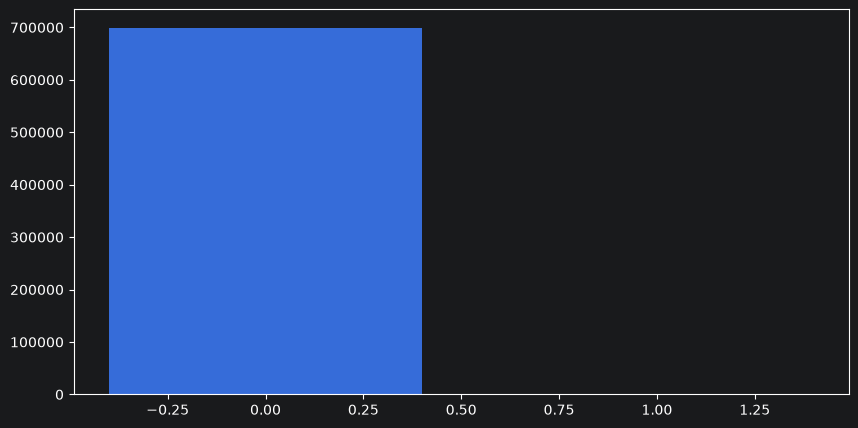

In [72]:
y = train['Arrival Delay in Minutes'].isnull().value_counts()
x = y.index.values

plt.figure(figsize=(10,5))
plt.bar(x,y)
plt.show()



In [73]:
median = train['Arrival Delay in Minutes'].median() # Pastikan median dari data TRAIN bukan TEST

train['Arrival Delay in Minutes'] = train['Arrival Delay in Minutes'].fillna(median).astype(int)
test['Arrival Delay in Minutes'] = test['Arrival Delay in Minutes'].fillna(median).astype(int)


In [74]:
print(train.duplicated().sum())

0


In [75]:
print(train.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699635 entries, 0 to 699634
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype 
---  ------                             --------------   ----- 
 0   id                                 699635 non-null  int64 
 1   Age                                699635 non-null  int64 
 2   Flight Distance                    699635 non-null  int64 
 3   Inflight wifi service              699635 non-null  int64 
 4   Departure/Arrival time convenient  699635 non-null  int64 
 5   Ease of Online booking             699635 non-null  int64 
 6   Gate location                      699635 non-null  int64 
 7   Food and drink                     699635 non-null  int64 
 8   Online boarding                    699635 non-null  int64 
 9   Seat comfort                       699635 non-null  int64 
 10  Inflight entertainment             699635 non-null  int64 
 11  On-board service                   699635 non-null  

# Encoding

In [76]:
from sklearn.preprocessing import LabelEncoder

# Bekerja di salinan agar sel ini aman dijalankan ulang
train_df = train.copy()
test_df = test.copy()

target_col = 'satisfaction'
ordinal_col = 'Class'
nominal_cols = ['Gender', 'Customer Type', 'Type of Travel']
id_col = 'id'

# 1. Label encoding untuk Class (fit di gabungan train+test, tanpa menyentuh target)
le = LabelEncoder()
le.fit(pd.concat([train_df[ordinal_col], test_df[ordinal_col]]).astype(str))
train_df[ordinal_col] = le.transform(train_df[ordinal_col].astype(str))
test_df[ordinal_col] = le.transform(test_df[ordinal_col].astype(str))

# 2. Target: satisfied = 1, selainnya = 0
y_train = (train_df[target_col] == 'satisfied').astype(int)

# Simpan id test untuk file submission, lalu buang dari fitur
test_ids = test_df[id_col].copy()

# 3. Buang target dan id dari fitur
train_features = train_df.drop(columns=[target_col, id_col])
test_features = test_df.drop(columns=[id_col])

# 4. Tandai asal baris, lalu gabungkan
train_features = train_features.assign(is_train=1)
test_features = test_features.assign(is_train=0)
df_combined = pd.concat([train_features, test_features], axis=0).reset_index(drop=True)

# 5. One-hot encoding
df_combined = pd.get_dummies(df_combined, columns=nominal_cols, drop_first=True, dtype=int)

# 6. Pisahkan kembali
X_train_clean = df_combined[df_combined['is_train'] == 1].drop(columns='is_train').reset_index(drop=True)
X_test_clean = df_combined[df_combined['is_train'] == 0].drop(columns='is_train').reset_index(drop=True)

print("Train:", X_train_clean.shape, "| Test:", X_test_clean.shape)  # harusnya (699635, 21) dan (299844, 21)

Train: (699635, 21) | Test: (299844, 21)


In [77]:
print(X_train_clean.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699635 entries, 0 to 699634
Data columns (total 21 columns):
 #   Column                             Non-Null Count   Dtype
---  ------                             --------------   -----
 0   Age                                699635 non-null  int64
 1   Flight Distance                    699635 non-null  int64
 2   Inflight wifi service              699635 non-null  int64
 3   Departure/Arrival time convenient  699635 non-null  int64
 4   Ease of Online booking             699635 non-null  int64
 5   Gate location                      699635 non-null  int64
 6   Food and drink                     699635 non-null  int64
 7   Online boarding                    699635 non-null  int64
 8   Seat comfort                       699635 non-null  int64
 9   Inflight entertainment             699635 non-null  int64
 10  On-board service                   699635 non-null  int64
 11  Leg room service                   699635 non-null  int64
 12  Ba

In [78]:
X = X_train_clean
y = y_train
X_test = X_test_clean

assert len(X) == len(y), "Jumlah baris X dan y harus sama"
assert list(X.columns) == list(X_test.columns), "Kolom X dan X_test harus sama"
assert all(d.kind in 'biuf' for d in X.dtypes), "Ada kolom non-numerik di X"

In [79]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
import lightgbm as lgb
import numpy as np

#Stratified cocok untuk data imbalance
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

#Tempat simpan prediksi
oof_preds = np.zeros(len(X))
test_preds = np.zeros(len(X_test))
fold_scores = []

# Setting Parameter
lgb_prams = {
    'objective' : 'binary', # Target pda kasus adalah klasifikasi biner
    'metric' : 'auc', #matriks evaluasi (Area Under the ROC Curve
    'boosting_type' : 'gbdt', # menentikan metode/aristektur dasar algoritma boosting (Gradient Boosting Decision Tree)
    'learning_rate' : 0.05, #Ukuran langkah belajar, makin kecil nilainy, makin hati-hati model dalam belajar
    'num_leaves' : 31, #niali default dari LGBM
    'feature_fraction' : 0.8,
    'random_state' : 42, #jumlah keacakan proses training
    'verbose' : -1 #kontrol jumlah log/peringatan saat training
}



In [85]:
import numpy as np
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

lgb_params = {
    'objective': 'binary',            # klasifikasi biner
    'metric': 'auc',                  # evaluasi dengan ROC AUC
    'boosting_type': 'gbdt',          # gradient boosting decision tree
    'learning_rate': 0.05,            # ukuran langkah tiap pohon
    'num_leaves': 31,                 # kompleksitas tiap pohon
    'feature_fraction': 0.8,          # tiap pohon hanya memakai 80% fitur
    'bagging_fraction': 0.8,          # tiap pohon hanya memakai 80% baris
    'bagging_freq': 1,                # bagging dilakukan setiap pohon
    'random_state': 42,
    'verbose': -1,
}

oof_preds = np.zeros(len(X))
test_preds = np.zeros(len(X_test))
fold_scores = []

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y)):
    print(f"==== Training fold {fold + 1} ====")

    X_tr, y_tr = X.iloc[train_idx], y.iloc[train_idx]
    X_va, y_va = X.iloc[val_idx], y.iloc[val_idx]

    dtrain = lgb.Dataset(X_tr, label=y_tr)
    dval = lgb.Dataset(X_va, label=y_va, reference=dtrain)

    model = lgb.train(
        lgb_params,
        dtrain,
        num_boost_round=3000,         # batas atas; early stopping yang menentukan
        valid_sets=[dval],
        valid_names=['val'],
        callbacks=[lgb.early_stopping(100, verbose=False), lgb.log_evaluation(200)],
    )

    oof_preds[val_idx] = model.predict(X_va, num_iteration=model.best_iteration)
    test_preds += model.predict(X_test, num_iteration=model.best_iteration) / skf.n_splits

    fold_auc = roc_auc_score(y_va, oof_preds[val_idx])
    fold_scores.append(fold_auc)
    print(f"Fold {fold + 1} | AUC = {fold_auc:.5f} | best_iter = {model.best_iteration}")

cv_score = roc_auc_score(y, oof_preds)
print(f"\nCV AUC (OOF)      = {cv_score:.5f}")
print(f"Rata-rata per fold = {np.mean(fold_scores):.5f} ± {np.std(fold_scores):.5f}")

==== Training fold 1 ====


C:\INAH-MINE\GEMASTIK-XIX\.venv\Lib\site-packages\sklearn\metrics\_ranking.py:469: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


Fold 1 | AUC = nan | best_iter = 1
==== Training fold 2 ====


C:\INAH-MINE\GEMASTIK-XIX\.venv\Lib\site-packages\sklearn\metrics\_ranking.py:469: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


Fold 2 | AUC = nan | best_iter = 1
==== Training fold 3 ====


C:\INAH-MINE\GEMASTIK-XIX\.venv\Lib\site-packages\sklearn\metrics\_ranking.py:469: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


... (2 outputs left out)

Fold 4 | AUC = nan | best_iter = 1
==== Training fold 5 ====


C:\INAH-MINE\GEMASTIK-XIX\.venv\Lib\site-packages\sklearn\metrics\_ranking.py:469: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(


Fold 5 | AUC = nan | best_iter = 1

CV AUC (OOF)      = nan
Rata-rata per fold = nan ± nan


C:\INAH-MINE\GEMASTIK-XIX\.venv\Lib\site-packages\sklearn\metrics\_ranking.py:469: UndefinedMetricWarning: Only one class is present in y_true. ROC AUC score is not defined in that case.
  warnings.warn(
